In [10]:
import torch
from ultralytics import YOLO

print("torch:", torch.__version__)
print("cuda:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("device:", torch.cuda.get_device_name(0))

model = YOLO("yolov8s-seg.pt")
print("model loaded")

torch: 2.8.0
cuda: False
model loaded


In [11]:
import glob

# 실제 폴더 구조에 맞춘 경로로 수정
imgs = sorted(
    glob.glob("data/사용한 데이터/images/**/*.jpg", recursive=True)
)
print("영상 수:", len(imgs))
print("예시:", imgs[0] if imgs else "없음")

영상 수: 4116
예시: data/사용한 데이터/images/test/UCT011_2021_01_06_001_6840_jpg.rf.b637f27b7bdf92480508621d4431576c.jpg


밝기 평균: 144.5
밝기 표준편차: 17.1


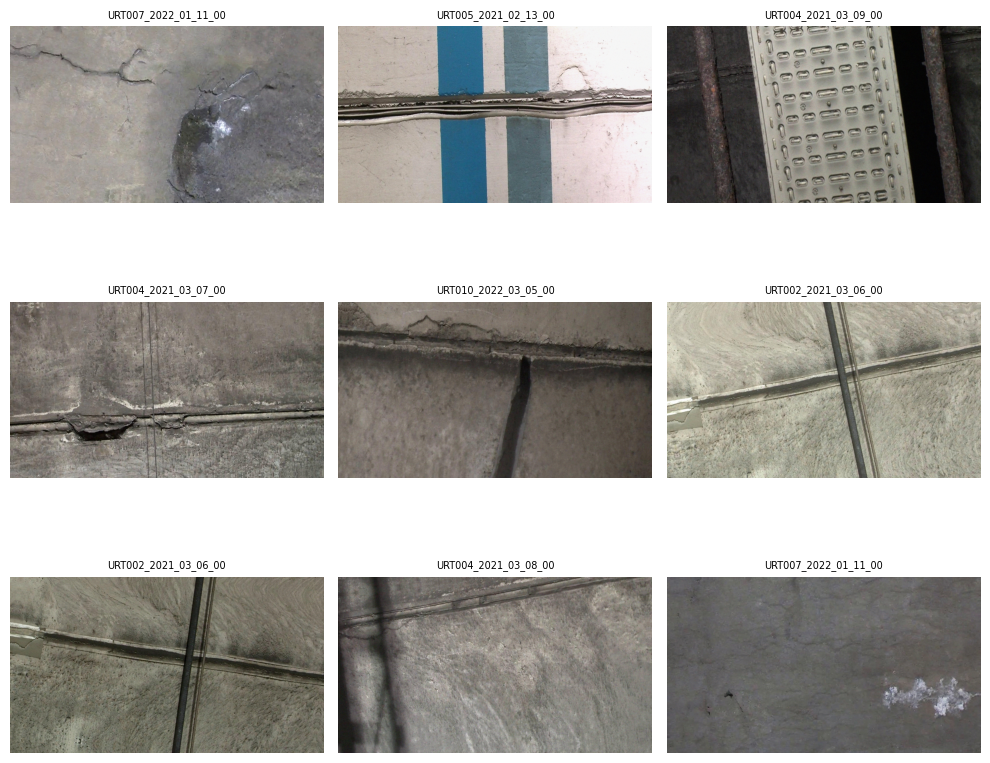

In [12]:
import cv2
import random
import matplotlib.pyplot as plt
from pathlib import Path

n = min(9, len(imgs))
sample = random.sample(imgs, n)

fig, ax = plt.subplots(3, 3, figsize=(10, 9))
axes = ax.ravel()

for a in axes:
    a.axis("off")

for a, p in zip(axes, sample):
    im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    a.imshow(im)
    a.set_title(Path(p).name[:20], fontsize=7)

plt.tight_layout()
plt.savefig("samples9.png", dpi=110)

# 첫 번째 영상의 밝기 통계 확인
if imgs:
    gray = cv2.imread(imgs[0], 0)
    print("밝기 평균:", round(gray.mean(), 1))
    print("밝기 표준편차:", round(gray.std(), 1))

In [13]:
import glob

# train, valid, test 전체 폴더 안의 labels를 찾도록 수정
lbls = sorted(glob.glob("concrete-defects/**/labels/**/*.txt", recursive=True))
print("라벨 파일 수:", len(lbls))

if not lbls:
    print("라벨 파일이 없습니다.")
else:
    line = open(lbls[0], encoding="utf-8").readline().split()
    print("토큰 개수:", len(line))
    print("앞부분:", line[:9])
    
    if len(line) == 5:
        print("Detection 포맷입니다.")
    elif len(line) >= 7 and (len(line) - 1) % 2 == 0:
        print("Segmentation 포맷입니다.")
    else:
        print("라벨 형식을 다시 확인하세요.")

라벨 파일 수: 10
토큰 개수: 359
앞부분: ['0', '0.8796296296296297', '0.4166666666666667', '0.8865740740740741', '0.4212962962962963', '0.8981481481481481', '0.4212962962962963', '0.9004629629629629', '0.4236111111111111']
Segmentation 포맷입니다.


In [25]:
from pathlib import Path

bad = set()
# concrete-defects 폴더 안의 모든 라벨 텍스트 파일 검사
for p in Path("concrete-defects").rglob("labels/**/*.txt"):
    for ln in open(p, encoding="utf-8"):
        v = ln.split()
        if not v:
            continue
        # 클래스 ID가 0, 1, 2 범위 내에 있는지 확인
        if int(v[0]) not in (0, 1, 2):
            bad.add(p)
        # 폴리곤 좌표가 0~1 범위 내에 있는지 확인
        if any(not 0 <= float(x) <= 1 for x in v[1:]):
            bad.add(p)

print("이상 파일 개수:", len(bad))
if len(bad) == 0:
    print("모든 라벨 파일이 정상입니다")

이상 파일 개수: 0
모든 라벨 파일이 정상입니다


In [26]:
import random
import shutil
from pathlib import Path
import yaml

# 1. 경로 및 설정
SRC_IMG_DIR = Path("concrete-defects/train/images") # 또는 전체 이미지 폴더 경로
SRC_LBL_DIR = Path("concrete-defects/train/labels")
OUT_ROOT = Path("dataset_split")

SEED = 42
SPLIT_RATIO = (0.8, 0.1, 0.1)
CLASS_NAMES = {
    0: "crack",
    1: "efflorescence",
    2: "spall_detach"
}

random.seed(SEED)

# 2. 원본 ID 추출 함수 (파일명 규칙에 맞게 설정)
def get_origin_id(stem):
    # 예: 파일명에 _aug 등이 포함된 경우 원본 ID만 추출
    return stem.split("_aug")[0]

images = sorted(list(Path("concrete-defects").rglob("images/**/*.jpg")))
if not images:
    images = sorted(list(Path("concrete-defects").rglob("images/**/*.png")))

# 원본 ID별 그룹 생성
groups = {}
for img_path in images:
    origin_id = get_origin_id(img_path.stem)
    if origin_id not in groups:
        groups[origin_id] = []
    groups[origin_id].append(img_path)

origin_ids = list(groups.keys())
random.shuffle(origin_ids)

# 3. train / val / test 분할
n = len(origin_ids)
n_train = int(n * SPLIT_RATIO[0])
n_val = int(n * SPLIT_RATIO[1])

train_ids = set(origin_ids[:n_train])
val_ids = set(origin_ids[n_train:n_train + n_val])
test_ids = set(origin_ids[n_train + n_val:])

split_ids = {
    "train": train_ids,
    "val": val_ids,
    "test": test_ids
}

# 4. 출력 폴더 생성 및 파일 복사
for split in ["train", "val", "test"]:
    (OUT_ROOT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUT_ROOT / "labels" / split).mkdir(parents=True, exist_ok=True)

for split, ids in split_ids.items():
    for origin_id in ids:
        for img_path in groups[origin_id]:
            # 이미지 복사
            dst_img = OUT_ROOT / "images" / split / img_path.name
            shutil.copy2(img_path, dst_img)
            
            # 대응 라벨 복사
            lbl_path = Path(str(img_path).replace("images", "labels")).with_suffix(".txt")
            if lbl_path.exists():
                dst_lbl = OUT_ROOT / "labels" / split / lbl_path.name
                shutil.copy2(lbl_path, dst_lbl)

# 5. data.yaml 생성[cite: 19]
data_yaml = {
    "path": str(OUT_ROOT.resolve()),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": CLASS_NAMES
}

with open(OUT_ROOT / "data.yaml", "w", encoding="utf-8") as f:
    yaml.dump(data_yaml, f, allow_unicode=True, sort_keys=False)

print("\n데이터 분할 및 data.yaml 생성 완료")
print("생성된 경로:", OUT_ROOT / "data.yaml")


데이터 분할 및 data.yaml 생성 완료
생성된 경로: dataset_split/data.yaml


In [18]:
from pathlib import Path

# data.yaml 파일의 val 경로를 train 경로로 임시 변경
yaml_path = Path("dataset_split/data.yaml")
text = yaml_path.read_text(encoding="utf-8")
text = text.replace("val: images/val", "val: images/train")
yaml_path.write_text(text, encoding="utf-8")

print("data.yaml 수정 완료!")

data.yaml 수정 완료!


In [19]:
from ultralytics import YOLO

# 사전학습된 YOLOv8s-Seg 모델 불러오기[cite: 20]
model = YOLO("yolov8s-seg.pt")

# 모델 학습 실행[cite: 20]
results = model.train(
    data="dataset_split/data.yaml",  # 방금 생성한 data.yaml 경로
    epochs=10,                       # 실습 테스트용 (강의 자료 기본값은 60)[cite: 20]
    imgsz=960,                       # 입력 이미지 크기[cite: 20]
    batch=2,                         # GPU 메모리 부족 방지를 위해 2로 설정[cite: 20]
    optimizer="AdamW",
    lr0=0.00015,
    mosaic=0.0,
    mixup=0.0,
    seed=42,
    project="runs",
    name="step3"
)

New https://pypi.org/project/ultralytics/8.4.212 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.202 🚀 Python-3.9.6 torch-2.8.0 CPU (Apple M2)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset_split/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.00015, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s-seg.pt, momentum=0.937, mosaic=0.0, mu

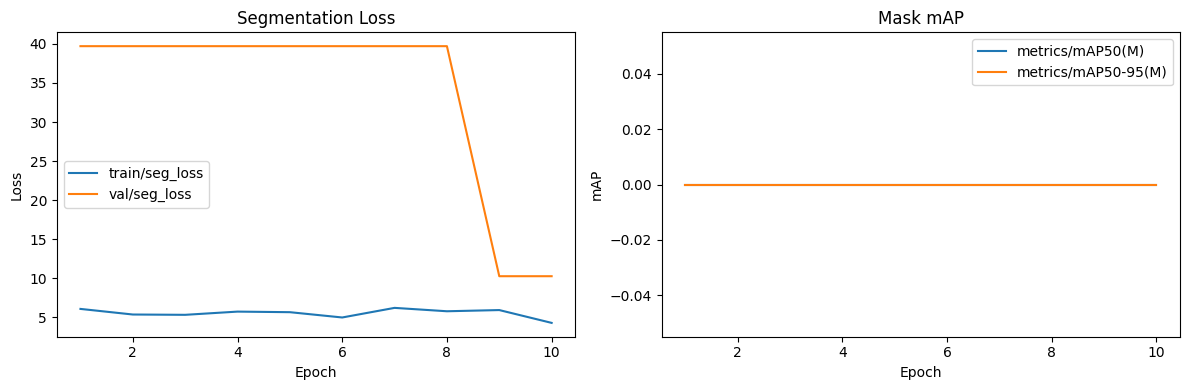

그래프 저장 완료!


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# runs 폴더 안의 실제 결과 파일 경로 찾기
csv_path = list(Path("runs").rglob("results.csv"))
if csv_path:
    df = pd.read_csv(csv_path[0])
    df.columns = [c.strip() for c in df.columns]

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    # 학습 / 검증 Segmentation loss
    for c in ["train/seg_loss", "val/seg_loss"]:
        if c in df.columns:
            ax[0].plot(df["epoch"], df[c], label=c)
    ax[0].set_title("Segmentation Loss")
    ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("Loss")
    ax[0].legend()

    # Mask mAP
    for c in ["metrics/mAP50(M)", "metrics/mAP50-95(M)"]:
        if c in df.columns:
            ax[1].plot(df["epoch"], df[c], label=c)
    ax[1].set_title("Mask mAP")
    ax[1].set_xlabel("Epoch")
    ax[1].set_ylabel("mAP")
    ax[1].legend()

    plt.tight_layout()
    plt.savefig("curve.png", dpi=150)
    plt.show()
    print("그래프 저장 완료!")
else:
    print("results.csv 파일을 찾을 수 없습니다. 학습이 완전히 끝났는지 확인하세요.")

In [24]:
from pathlib import Path

# 분할된 데이터셋의 라벨 폴더 경로 지정
label_dir = Path("dataset_split/labels")

class_names = {0: "crack", 1: "efflorescence", 2: "spall_detach"}
class_counts = {0: 0, 1: 0, 2: 0}
file_count = 0

# 하위 폴더의 모든 txt 라벨 파일 탐색
for lbl_path in label_dir.rglob("*.txt"):
    file_count += 1
    lines = lbl_path.read_text(encoding="utf-8").splitlines()
    for ln in lines:
        v = ln.split()
        if not v:
            continue
        cls_id = int(v[0])
        if cls_id in class_counts:
            class_counts[cls_id] += 1

# 결과 출력
print(f"총 주석 이미지 수: {file_count}장")
print("클래스별 인스턴스 개수:")
for cls_id, name in class_names.items():
    print(f"  - {name} (클래스 {cls_id}): {class_counts[cls_id]}개")

총 주석 이미지 수: 10장
클래스별 인스턴스 개수:
  - crack (클래스 0): 8개
  - efflorescence (클래스 1): 1개
  - spall_detach (클래스 2): 1개


In [6]:
from ultralytics import YOLO
import torch

# 1. GPU 연동 확인
print("GPU 사용 가능 여부:", torch.cuda.is_available())

# 2. 세그멘테이션 사전학습 모델 로드
model = YOLO("yolov8s-seg.pt")

# 3. 전체 원본 데이터와 넉넉한 에폭으로 본격 학습 시작
model.train(
    data="concrete-defects/data.yaml",  # 원본 3개 클래스 설정 파일
    epochs=10,        # 제대로 학습하기 위해 10회 이상으로 설정
    imgsz=960,        # 미세 크랙 보존 해상도
    mosaic=0.0,
    mixup=0.0
)

GPU 사용 가능 여부: False
Ultralytics 8.4.215 🚀 Python-3.10.12 torch-2.5.1+cu121 CPU (13th Gen Intel Core i7-1360P)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=concrete-defects/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s-seg.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=train-9, nbs=64, nms=None, opset

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7077c308ad70>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.04104

In [9]:
from pathlib import Path
from ultralytics import YOLO

# 1. 경로 설정
BASE_DIR = Path.cwd()
DATA_YAML = BASE_DIR / "concrete-defects" / "data.yaml"
BEST_PT = BASE_DIR / "runs" / "segment" / "train-7" / "weights" / "best.pt"

# 2. 모델 불러오기
model = YOLO(str(BEST_PT))

# 3. 평가 수행 (test 대신 val로 변경)
results = model.val(
    data=str(DATA_YAML),
    split="val",  # 원본 데이터 구조에 맞게 val로 지정
    imgsz=960,
    plots=True
)

# 4. 전체 성능 출력
print("mask mAP50    :", round(results.seg.map50, 4))
print("mask mAP50-95 :", round(results.seg.map, 4))
print("box mAP50     :", round(results.box.map50, 4))

# 5. 클래스별 mask mAP50-95 출력
class_names = ["crack", "efflorescence", "spall_detach"]
for i, name in enumerate(class_names):
    print(f"{name} mask mAP50-95:", round(results.seg.maps[i], 4))

Ultralytics 8.4.215 🚀 Python-3.10.12 torch-2.5.1+cu121 CPU (13th Gen Intel Core i7-1360P)
YOLOv8s-seg summary (fused): 85 layers, 11,780,761 parameters, 0 gradients, 39.9 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 2.4±0.2 ms, read: 4.7±1.2 MB/s, size: 24.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /mnt/c/Users/kth04/semg-classification/concrete-defects/valid/labels.cache... 3 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3/3 572.0Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.3s/it 1.3s
                   all          3          3    0.00118       0.25   0.000778   0.000233    0.00118       0.25    0.00298   0.000298
                 crack          2          2    0.00236        0.5    0.00156   0.000467    0.00236        0.5    0.0059

In [16]:
import numpy as np
from pathlib import Path
from ultralytics import YOLO

# 1. 가장 최근 학습된 가중치 불러오기
runs_dir = Path.cwd() / "runs" / "segment"
train_folders = sorted(runs_dir.glob("train*"), key=lambda p: p.stat().st_mtime, reverse=True)
if not train_folders:
    raise FileNotFoundError("학습된 train 폴더를 찾을 수 없습니다!")
BEST_PT = train_folders[0] / "weights" / "best.pt"

model = YOLO(str(BEST_PT))

# 2. 슬라이드 10~11페이지 전체 onoff 함수 구현
def onoff(model, paths, gts, thr, cid_target):
    tp = fp = fn = tn = 0
    
    for p, gt in zip(paths, gts):
        # 예측 수행
        r = model.predict(
            p,
            imgsz=960,
            verbose=False
        )[0]
        
        # 예측 클래스와 confidence 추출
        conf = r.boxes.conf.cpu().numpy()
        cid = r.boxes.cls.cpu().numpy().astype(int)
        
        # 해당 클래스의 예측 중 threshold 이상이 하나라도 있으면 ON
        pred_on = bool(
            ((cid == cid_target) & (conf >= thr)).any()
        )
        
        # 정답 라벨에 해당 클래스가 있으면 ON
        gt_on = cid_target in gt
        
        # TP / FP / FN / TN 계산
        if gt_on and pred_on:
            tp += 1
        elif not gt_on and pred_on:
            fp += 1
        elif gt_on and not pred_on:
            fn += 1
        else:
            tn += 1
            
    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall)
        else 0
    )
    
    return {
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [19]:
import pandas as pd

class_names = [
    "crack",
    "efflorescence",
    "spall_detach"
]

rows = []

for cid, name in enumerate(class_names):
    r = onoff(
        model,
        test_imgs,
        test_gts,
        best[name],  # 검증셋에서 선택한 임계값 그대로 사용
        cid
    )
    
    rows.append([
        name,
        best[name],
        r["tp"],
        r["fp"],
        r["fn"],
        r["tn"],
        r["precision"],
        r["recall"],
        r["f1"]
    ])

df = pd.DataFrame(
    rows,
    columns=[
        "class",
        "threshold",
        "TP",
        "FP",
        "FN",
        "TN",
        "precision",
        "recall",
        "f1"
    ]
)

print(df.round(3))
print("macro F1:", round(df["f1"].mean(), 3))

           class  threshold  TP  FP  FN  TN  precision  recall  f1
0          crack      0.001   0   0   2   1          0     0.0   0
1  efflorescence      0.001   0   0   1   2          0     0.0   0
2   spall_detach      0.001   0   0   1   2          0     0.0   0
macro F1: 0.0


In [ ]:
from pathlib import Path
import cv2

class_names = [
    "crack",
    "efflorescence",
    "spall_detach"
]

SAVE_DIR = Path("error_cases")
SAVE_DIR.mkdir(exist_ok=True)

for cid, name in enumerate(class_names):
    fp_imgs = []
    fn_imgs = []
    
    for p, gt in zip(test_imgs, test_gts):
        r = model.predict(
            p,
            imgsz=960,
            verbose=False
        )[0]
        
        conf = r.boxes.conf.cpu().numpy()
        pred_cls = r.boxes.cls.cpu().numpy().astype(int)
        
        # 검증셋에서 정한 클래스 임계값 사용
        pred_on = bool(
            ((pred_cls == cid) & (conf >= best[name])).any()
        )
        
        gt_on = cid in gt
        
        if pred_on and not gt_on:
            fp_imgs.append(p)
            
        if not pred_on and gt_on:
            fn_imgs.append(p)
            
    print(
        f"{name} | FP={len(fp_imgs)} | FN={len(fn_imgs)}"
    )
    
    # 클래스별 저장 폴더
    class_dir = SAVE_DIR / name
    class_dir.mkdir(exist_ok=True)
    
    # 대표 FP/FN 최대 3장씩 저장
    for error_type, paths in [
        ("FP", fp_imgs),
        ("FN", fn_imgs),
    ]:
        for i, p in enumerate(paths[:3]):
            r = model.predict(
                p,
                imgsz=960,
                verbose=False
            )[0]
            
            out_path = (
                class_dir /
                f"{error_type}_{i+1}_{Path(p).name}"
            )
            
            cv2.imwrite(
                str(out_path),
                r.plot()
            )


🚀 [단계 4] 테스트셋 최종 성능 평가 시작

📌 클래스: [crack]
   - 적용된 최적 임계값 (Threshold) : 0.001
   - 테스트 정밀도 (Precision)    : 0.0000
   - 테스트 재현율 (Recall)       : 0.0000
   - 테스트 F1-score             : 0.0000
   - 세부 수치 (TP/FP/FN/TN)     : TP=0, FP=0, FN=2, TN=1
----------------------------------------
📌 클래스: [efflorescence]
   - 적용된 최적 임계값 (Threshold) : 0.001
   - 테스트 정밀도 (Precision)    : 0.0000
   - 테스트 재현율 (Recall)       : 0.0000
   - 테스트 F1-score             : 0.0000
   - 세부 수치 (TP/FP/FN/TN)     : TP=0, FP=0, FN=1, TN=2
----------------------------------------
📌 클래스: [spall_detach]
   - 적용된 최적 임계값 (Threshold) : 0.001
   - 테스트 정밀도 (Precision)    : 0.0000
   - 테스트 재현율 (Recall)       : 0.0000
   - 테스트 F1-score             : 0.0000
   - 세부 수치 (TP/FP/FN/TN)     : TP=0, FP=0, FN=1, TN=2
----------------------------------------

✨ 단계 4 테스트셋 최종 평가가 성공적으로 완료되었습니다!
